## Heatmap

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

conn = sqlite3.connect('../data/checking-logs.sqlite')
query = """
    SELECT
        uid,
        timestamp
    FROM
        checker
    WHERE
        uid LIKE 'user_%'
"""
df = pd.read_sql(query, conn, parse_dates=['timestamp'])
conn.close()

### data processing

In [2]:
df['hour'] = df['timestamp'].dt.hour
df['weekday'] = df['timestamp'].dt.day_name().str[:3]

user_order = df['uid'].value_counts().sort_values(ascending=False).index

## matrix 1
df_pivot_day = df.groupby(['weekday', 'uid']).size().unstack(fill_value=0)
days_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']      
df_pivot_day = df_pivot_day.reindex(days_order)
df_pivot_day = df_pivot_day.reindex(columns=user_order)


## matrix 2
df_pivot_hour = df.groupby(['hour', 'uid']).size().unstack(fill_value=0)
df_pivot_hour = df_pivot_hour.reindex(range(24), fill_value=0)
df_pivot_hour = df_pivot_hour.reindex(columns=user_order)

df_pivot_day.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7 entries, Mon to Sun
Data columns (total 30 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_4   7 non-null      int64
 1   user_14  7 non-null      int64
 2   user_2   7 non-null      int64
 3   user_25  7 non-null      int64
 4   user_19  7 non-null      int64
 5   user_26  7 non-null      int64
 6   user_20  7 non-null      int64
 7   user_31  7 non-null      int64
 8   user_10  7 non-null      int64
 9   user_3   7 non-null      int64
 10  user_29  7 non-null      int64
 11  user_13  7 non-null      int64
 12  user_28  7 non-null      int64
 13  user_24  7 non-null      int64
 14  user_12  7 non-null      int64
 15  user_8   7 non-null      int64
 16  user_1   7 non-null      int64
 17  user_21  7 non-null      int64
 18  user_30  7 non-null      int64
 19  user_18  7 non-null      int64
 20  user_17  7 non-null      int64
 21  user_16  7 non-null      int64
 22  user_27  7 non-null      int64


In [3]:
df_pivot_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 30 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_4   24 non-null     int64
 1   user_14  24 non-null     int64
 2   user_2   24 non-null     int64
 3   user_25  24 non-null     int64
 4   user_19  24 non-null     int64
 5   user_26  24 non-null     int64
 6   user_20  24 non-null     int64
 7   user_31  24 non-null     int64
 8   user_10  24 non-null     int64
 9   user_3   24 non-null     int64
 10  user_29  24 non-null     int64
 11  user_13  24 non-null     int64
 12  user_28  24 non-null     int64
 13  user_24  24 non-null     int64
 14  user_12  24 non-null     int64
 15  user_8   24 non-null     int64
 16  user_1   24 non-null     int64
 17  user_21  24 non-null     int64
 18  user_30  24 non-null     int64
 19  user_18  24 non-null     int64
 20  user_17  24 non-null     int64
 21  user_16  24 non-null     int64
 22  user_27  24 non-null     int

## visual function

In [ ]:
def plot_heatmap(ax, data, cmap_name):
    im = ax.imshow(data, cmap=cmap_name, aspect='auto')

    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels(data.columns, rotation=90, fontsize=10)

    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels(data.index, fontsize=10)


    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    plt.colorbar(im, cax=cax)

## final heatmap

In [6]:
df_pivot_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 30 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_4   24 non-null     int64
 1   user_14  24 non-null     int64
 2   user_2   24 non-null     int64
 3   user_25  24 non-null     int64
 4   user_19  24 non-null     int64
 5   user_26  24 non-null     int64
 6   user_20  24 non-null     int64
 7   user_31  24 non-null     int64
 8   user_10  24 non-null     int64
 9   user_3   24 non-null     int64
 10  user_29  24 non-null     int64
 11  user_13  24 non-null     int64
 12  user_28  24 non-null     int64
 13  user_24  24 non-null     int64
 14  user_12  24 non-null     int64
 15  user_8   24 non-null     int64
 16  user_1   24 non-null     int64
 17  user_21  24 non-null     int64
 18  user_30  24 non-null     int64
 19  user_18  24 non-null     int64
 20  user_17  24 non-null     int64
 21  user_16  24 non-null     int64
 22  user_27  24 non-null     int

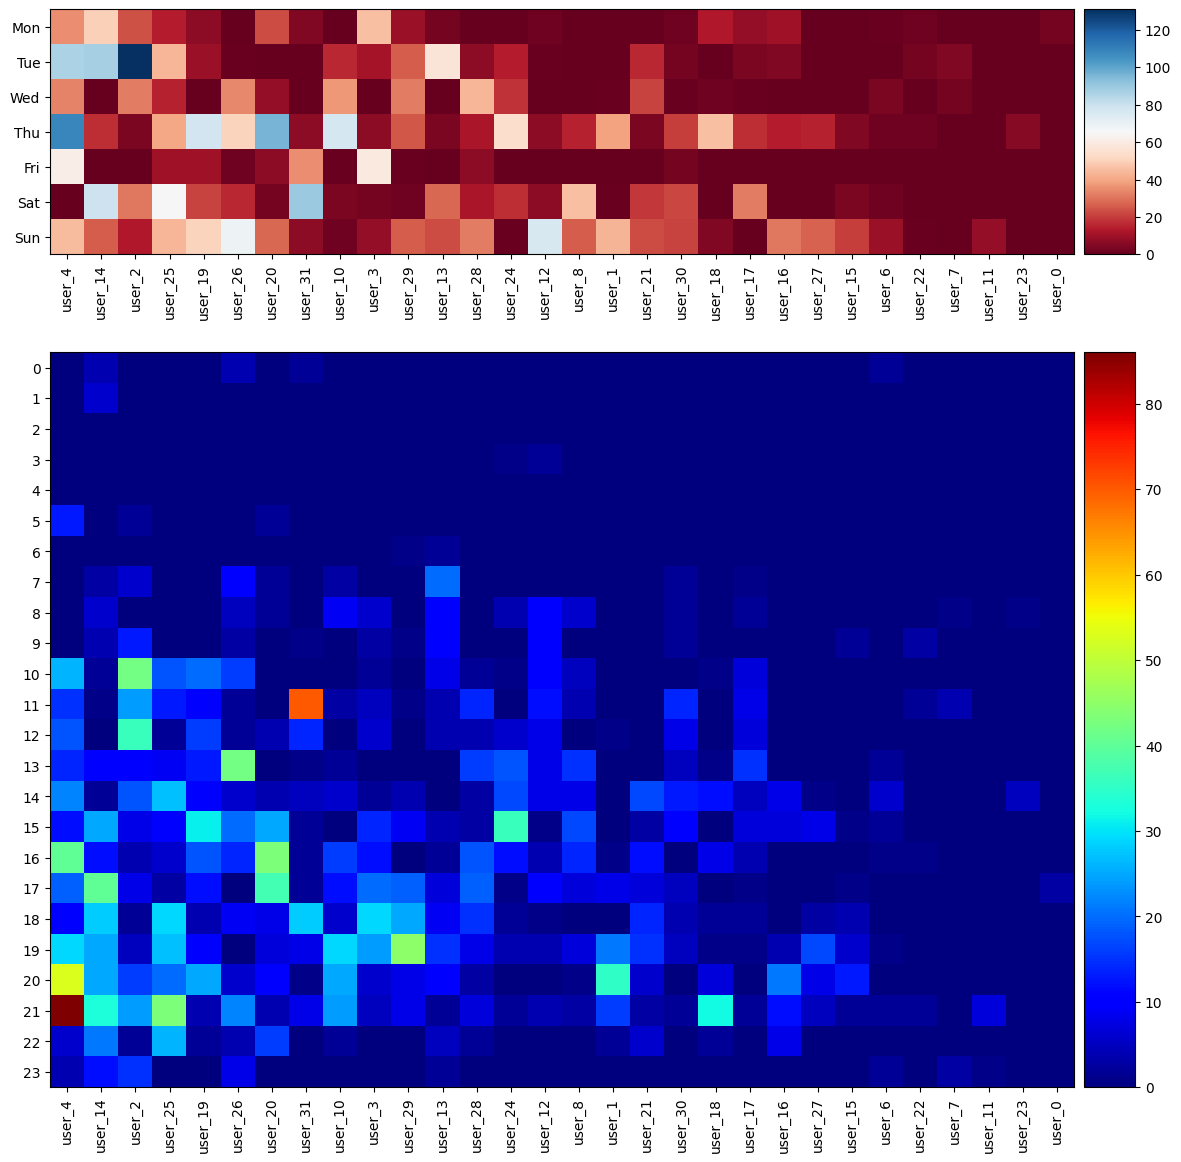

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 14), 
                         gridspec_kw={'height_ratios': [1, 3]})

plot_heatmap(axes[0], df_pivot_day, 'RdBu')
plot_heatmap(axes[1], df_pivot_hour, 'jet')
plt.show()

## Which user has the most commits on Tuesday?

Answer: user_2

## Which user has the most commits on Thursday?

Answer: user_4

## On which weekday do users not like to make a lot of commits?

Answer: Friday

## Which user made the largest number of commits at which hour?

Answer: user_4, 21